### 2. Data cleaning
Now the data is ingested, the data will be cleaned and explored further to scope the possible avenues of later analysis prior to any work with AI libraries and packages. First, checking for duplicate values and comparing the csv files and json files to ensure all petitions captured. Will then check for missing or faulty data in action, background and details column.

In [1]:
# importing all relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import pyarrow as pa
import pyarrow.parquet as pq

In [2]:
# reading in the data from parquet files
petitions_metadata_df = pd.read_csv('data\petitions_metadata.csv')

petitions_table = pq.read_table('data\petitions_data.parquet')
countries_table = pq.read_table('data\petitions_country_data.parquet')
regions_table = pq.read_table('data\petitions_region_data.parquet')
constituencies_table = pq.read_table('data\petitions_constituency_data.parquet')

petitions_df = petitions_table.to_pandas()
countries_df = countries_table.to_pandas()
regions_df = regions_table.to_pandas()
constituencies_df = constituencies_table.to_pandas()

Removing first any nulls that I am aware of from the ingestion process. Then, looking at the shape of the working file to check for futher null data and missing entries.

In [3]:
# removing empty entries where the petition information was not accessible (due to moderation)
petitions_df = petitions_df[petitions_df['action']!=""]

In [4]:
# printing shape and info
print(petitions_df.shape)
petitions_df.info()

(116977, 8)
<class 'pandas.core.frame.DataFrame'>
Index: 116977 entries, 0 to 31729
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   petition_id      116977 non-null  int64 
 1   url              116977 non-null  object
 2   action           116977 non-null  object
 3   background       116977 non-null  object
 4   details          116976 non-null  object
 5   created_at       116977 non-null  object
 6   signature_count  116977 non-null  int64 
 7   parliament       116977 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 8.0+ MB


1 null entry which will be removed.

In [5]:
petitions_df = petitions_df.dropna()
petitions_df.shape

(116976, 8)

In [6]:
# converting date column to date type
petitions_df['created_at'] = pd.to_datetime(petitions_df['created_at'])

In [7]:
# checking the rest of the types are correct
petitions_df.dtypes

petition_id                      int64
url                             object
action                          object
background                      object
details                         object
created_at         datetime64[ns, UTC]
signature_count                  int64
parliament                       int64
dtype: object

In [8]:
petitions_df['text'] = petitions_df['action'] + ", " + petitions_df['background'] + ", " + petitions_df['details']
petitions_df.drop('action',axis=1, inplace=True)
petitions_df.drop('background', axis=1, inplace=True)

In [9]:
petitions_df.head()

,petition_id,url,details,created_at,signature_count,parliament,text
0,700001,https://petition.parliament.uk/petitions/70000...,I know firsthand the physical and emotional ch...,2024-10-30 14:20:17.653000+00:00,939,4,Fund reconstruction surgery and psychosexual t...
1,700005,https://petition.parliament.uk/petitions/70000...,I think the Single Market would bring inward i...,2024-10-30 14:28:44.914000+00:00,136651,4,Apply for the UK to join the European Union as...
2,700006,https://petition.parliament.uk/petitions/70000...,The real black hole in the UK’s economy is all...,2024-10-30 14:32:33.904000+00:00,10,4,"Rejoin the European Union, The UK Government s..."
3,700007,https://petition.parliament.uk/petitions/70000...,I believe that the ability for violent offende...,2024-10-30 14:34:44.936000+00:00,1216,4,Require dating apps to ensure ID and DBS check...
4,700009,https://petition.parliament.uk/petitions/70000...,"Currently, many Long Covid sufferers are unabl...",2024-10-30 14:53:44.200000+00:00,716,4,"Fund Covid booster vaccines for all, with prio..."


This is the final format of the table for the petitions text data and consists of 7 columns: 3 containing numerical values and 4 containing text data. The petition ID and url both uniquely identify a petition and the text column provides the basis for the text analysis in the modeling stage. The numerical signature count column will then provide weighting for this analysis.\
\
Lastly, removing petitions with signature count below 20.

In [10]:
petition_ratio = (petitions_df[petitions_df['signature_count'] >= 20].shape[0] / petitions_df.shape[0]) * 100
print(f"Petitions with over 10 signatures consist of {round(petition_ratio, 2)}% of all petitions")

Petitions with over 10 signatures consist of 37.16% of all petitions


In [11]:
petitions_df = petitions_df[petitions_df['signature_count'] >= 20]

In [12]:
petitions_df.shape

(43473, 7)

In [13]:
petitions_text_pa = pa.Table.from_pandas(petitions_df)
pq.write_table(petitions_text_pa, 'data\petitions_clean_data.parquet')

Repeating the same for the countries, region and constituency data.

In [14]:
# printing shape and info
print(countries_df.shape)
countries_df.info()

(213594, 5)
<class 'pandas.core.frame.DataFrame'>
Index: 213594 entries, 0 to 0
Data columns (total 5 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   name             213594 non-null  object
 1   code             213594 non-null  object
 2   signature_count  213594 non-null  int64 
 3   petition_id      213594 non-null  int64 
 4   ID               213594 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 9.8+ MB


In [15]:
# printing shape and info
print(regions_df.shape)
regions_df.info()

(321937, 5)
<class 'pandas.core.frame.DataFrame'>
Index: 321937 entries, 0 to 4
Data columns (total 5 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   name             321937 non-null  object
 1   ons_code         321937 non-null  object
 2   signature_count  321937 non-null  int64 
 3   petition_id      321937 non-null  int64 
 4   ID               321937 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 14.7+ MB


In [16]:
# printing shape and info
print(constituencies_df.shape)
constituencies_df.info()

(5339624, 6)
<class 'pandas.core.frame.DataFrame'>
Index: 5339624 entries, 0 to 9
Data columns (total 6 columns):
 #   Column           Dtype 
---  ------           ----- 
 0   name             object
 1   ons_code         object
 2   mp               object
 3   signature_count  int64 
 4   petition_id      int64 
 5   ID               int64 
dtypes: int64(3), object(3)
memory usage: 285.2+ MB


There's no info given for null data for constituencies from the info function so looking at this more below and replacing any nulls.

In [17]:
# printing sum of NA values
constituencies_df.isna().sum()

name                     0
ons_code                 0
mp                 4951349
signature_count          0
petition_id              0
ID                       0
dtype: int64

There is a lot of missing data on the MPs for given constituencies, it appears generally this information isn't filled in and so the column will be dropped.

In [18]:
# dropping mp column as is unhelpful
constituencies_df.drop('mp', axis=1, inplace=True)

In [19]:
petitions_constituencies_pa = pa.Table.from_pandas(constituencies_df)
pq.write_table(petitions_constituencies_pa, 'data\petitions_cle_data.parquet')

### Data exploration
For the data exploration, the data on signature count is investigated further including looking at spread. Breakdown by country, region and constituency will also be explored. Little will be done with text data and this will receive more attention in the preprocessing stage.\
\
First looking at simple statistics and a Q-Q plot to get an idea of the model.

In [20]:
import statistics

# fitlering signatures by signature count as above and saving to a variable for reference later
filtered_metadata = petitions_metadata_df[petitions_metadata_df['Signatures Count']>=20]
signature_scores = filtered_metadata['Signatures Count']

# calculating average values
mean = statistics.mean(signature_scores)
median = statistics.median(signature_scores)
mode = statistics.mode(signature_scores)
stdev = statistics.stdev(signature_scores)

print('mean: ', mean, '\nmode:', mode, '\nmedian:', median, '\nstandard deviation:', stdev)

mean:  3079.7867882388155 
mode: 21 
median: 39 
standard deviation: 44946.510080830834


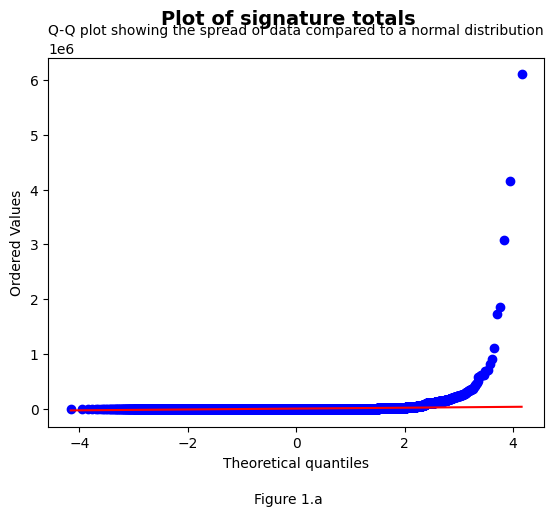

In [21]:
#importing relevant libraries for visualisation
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Q-Q Plot
stats.probplot(signature_scores, dist="norm", plot=plt)
# adding text labels
plt.suptitle("Plot of signature totals", fontsize=14, weight='bold')
plt.title("Q-Q plot showing the spread of data compared to a normal distribution", fontsize=10)
plt.figtext(0.5, -0.05, "Figure 1.a", ha="center", fontsize=10)
plt.show()

For a normal distribution, a straight diagonal with a positive correlation would be expected. However, the data is heavily skewed to the right meaning there is high variation among petitions with large amounts of signatures but most petitions have smaller numbers of signatures. This can be seen further with the box plot. This is important to note when considering what topics give petitions large amounts of votes and why certain topics create these outliers. For the sake of getting an idea of what petitions are more 'standard' we may want to remove this.\
\
Subsetting the data and looking again at Q-Q plot to see if distribution changes over time. Picking first, middle and last value for years to have a look at this.

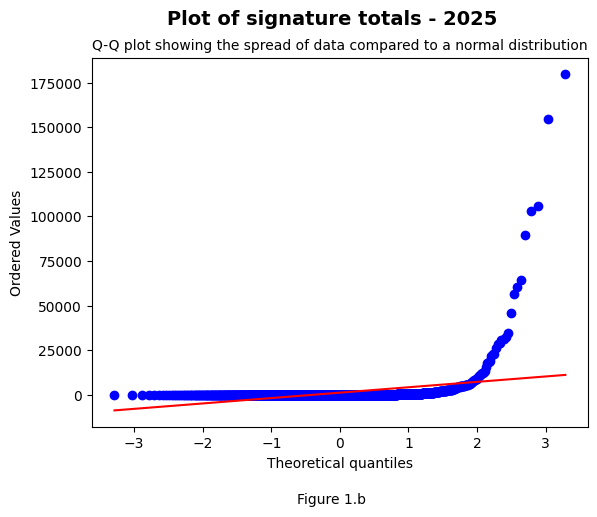

In [22]:
petitions_2025 = petitions_df.loc[petitions_df['created_at'].dt.year == 2025]
signature_scores = petitions_2025['signature_count']

# Q-Q Plot
stats.probplot(signature_scores, dist="norm", plot=plt)
# adding text labels
plt.suptitle("Plot of signature totals - 2025", fontsize=14, weight='bold')
plt.title("Q-Q plot showing the spread of data compared to a normal distribution", fontsize=10)
plt.figtext(0.5, -0.05, "Figure 1.b", ha="center", fontsize=10)
plt.show()

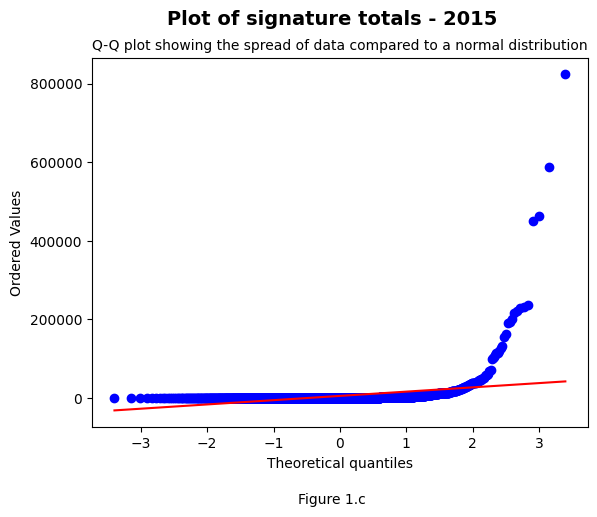

In [23]:
petitions_2015 = petitions_df.loc[petitions_df['created_at'].dt.year == 2015]
signature_scores = petitions_2015['signature_count']

# Q-Q Plot
stats.probplot(signature_scores, dist="norm", plot=plt)
# adding text labels
plt.suptitle("Plot of signature totals - 2015", fontsize=14, weight='bold')
plt.title("Q-Q plot showing the spread of data compared to a normal distribution", fontsize=10)
plt.figtext(0.5, -0.05, "Figure 1.c", ha="center", fontsize=10)
plt.show()

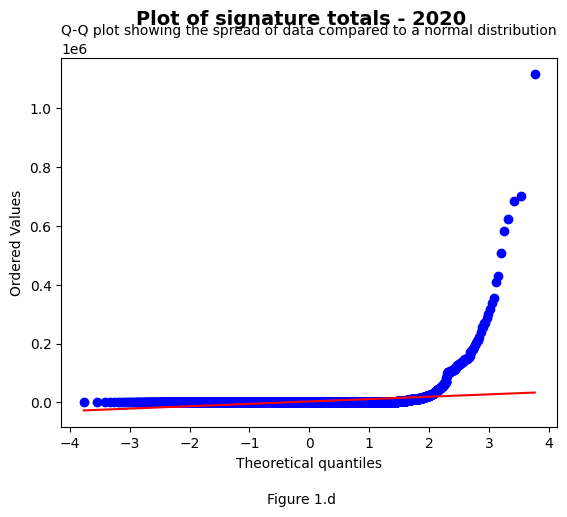

In [24]:
petitions_2020 = petitions_df.loc[petitions_df['created_at'].dt.year == 2020]
signature_scores = petitions_2020['signature_count']

# Q-Q Plot
stats.probplot(signature_scores, dist="norm", plot=plt)
# adding text labels
plt.suptitle("Plot of signature totals - 2020", fontsize=14, weight='bold')
plt.title("Q-Q plot showing the spread of data compared to a normal distribution", fontsize=10)
plt.figtext(0.5, -0.05, "Figure 1.d", ha="center", fontsize=10)
plt.show()

The plot remains showing no correlation to a normal distribution with a strong right skew. To show this further, a box plot will be used on the full dataset.

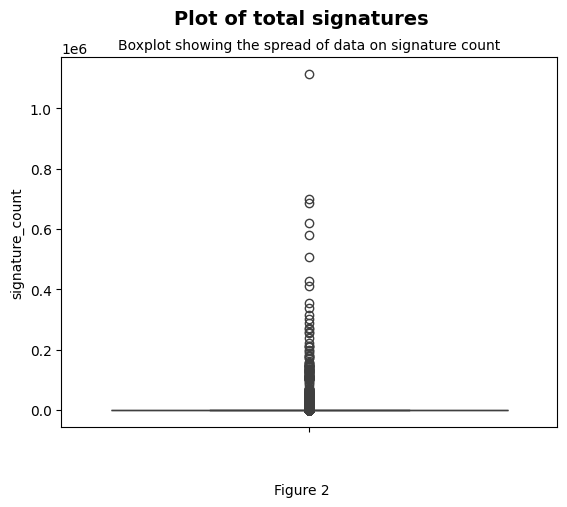

In [25]:
# creating a boxplot
sns.boxplot(signature_scores)

# adding text labels
plt.suptitle("Plot of total signatures", fontsize=14, weight='bold')
plt.title("Boxplot showing the spread of data on signature count", fontsize=10)
plt.figtext(0.5, -0.03, "Figure 2", ha="center", fontsize=10)
plt.show()

Now moving onto plotting some of the data for countries, regions and constituencies to see the spread. Each of these datasets will be mapped on bar plots or tables (depending on outliers to best demonstrate spread) to see the spread of signatures and the areas with highest count etc.,

In [26]:
# creating a function which will create an aggregate table of countries/regions/constituencies and signatures
# (grouping by area and summing signatures)
def aggregate_signatures(df, area_type):
    """
    Aggregates signatures for the given dataframe over the inputted area type e.g. region/constituency
    :param df: dataframe from which to aggregate signatures by area
    :param area_type: string indicating the scope of area to aggregate by e.g. consistuency
    :return: dataframe of signatures grouped by area
    """
    signatures = []
    # looping through geographical locations
    for area in df['name'].unique():
        # summing signatures for given location
        signature_count = df[df['name']==area]['signature_count'].sum()
        # adding results to dictionary
        signature = {
            area_type: area,
            'signature_count': signature_count
            }
        signatures.append(signature)
    area_agg = pd.DataFrame(signatures)
    return area_agg

In [27]:
# plotting a bar plot with top 10 values missing the first value as the UK signatures hugely skews the data
country_agg = aggregate_signatures(countries_df, 'country')

country_agg.sort_values(by='signature_count', ascending=False)[0:10]

,country,signature_count
11,United Kingdom,132266028
37,France,331839
89,Spain,247189
12,United States,192360
0,Australia,178637
47,Hong Kong,146916
4,Germany,118330
1,Canada,91373
5,Ireland,89289
69,Netherlands,58059


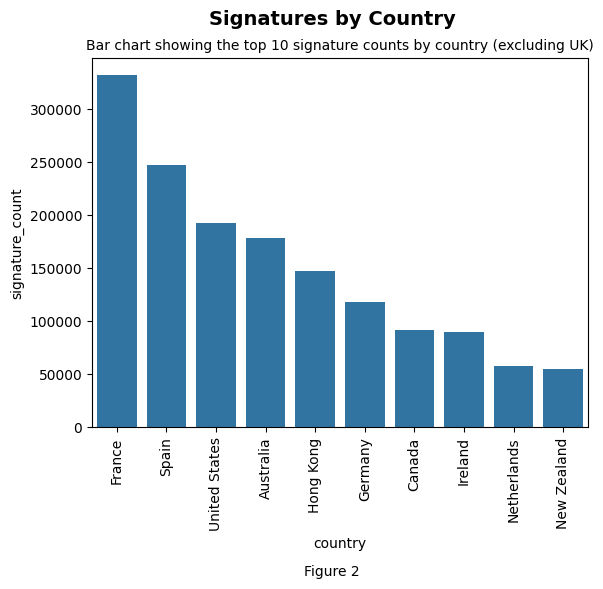

In [28]:
ax = sns.barplot(data = country_agg.sort_values(by='signature_count', ascending=False)[1:11], x="country", y="signature_count")
ax.tick_params(axis='x', labelrotation=90)
# adding text labels
plt.suptitle("Signatures by Country", fontsize=14, weight='bold')
plt.title("Bar chart showing the top 10 signature counts by country (excluding UK)", fontsize=10)
plt.figtext(0.5, -0.2, "Figure 2", ha="center", fontsize=10)
plt.show()

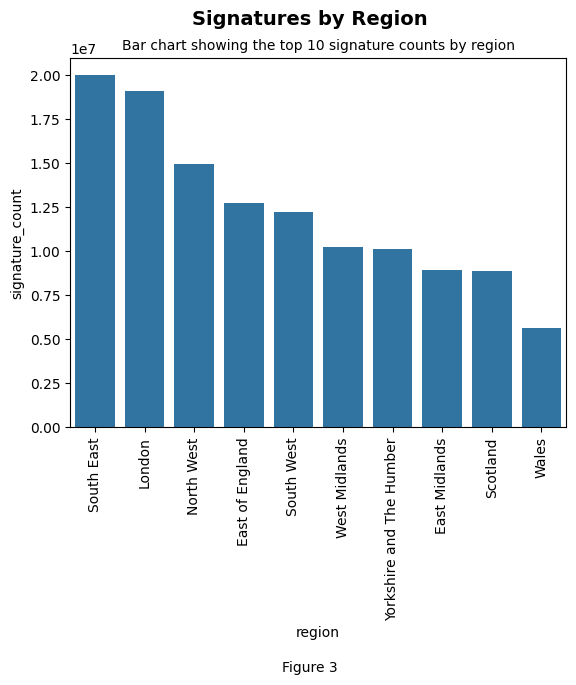

In [29]:
# calling aggregate function to aggregate regions and creating bar plot with top 10 values
region_agg = aggregate_signatures(regions_df, 'region')
ax = sns.barplot(data = region_agg.sort_values(by='signature_count', ascending=False)[0:10], x="region", y="signature_count")
ax.tick_params(axis='x', labelrotation=90)
# adding text labels
plt.suptitle("Signatures by Region", fontsize=14, weight='bold')
plt.title("Bar chart showing the top 10 signature counts by region", fontsize=10)
plt.figtext(0.5, -0.4, "Figure 3", ha="center", fontsize=10)

plt.show()

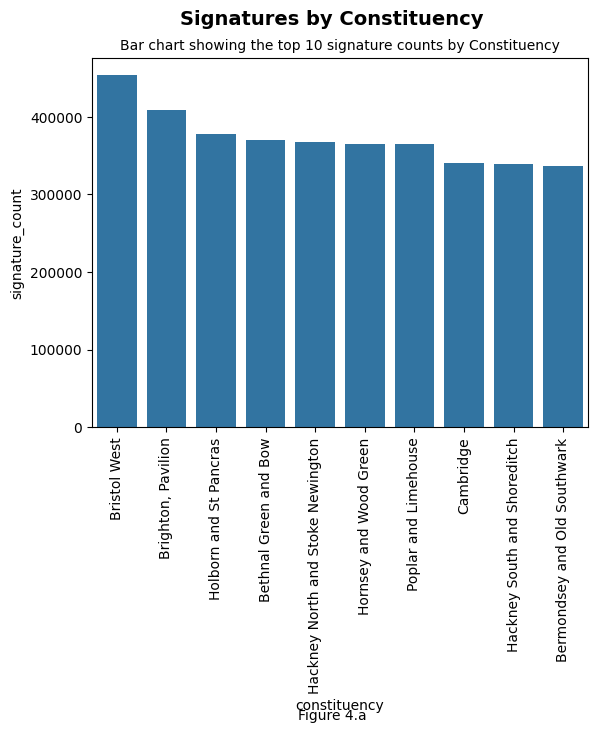

In [30]:
# calling aggregate function to aggregate constituencies and creating bar plot with top 10 values
constituency_agg = aggregate_signatures(constituencies_df, 'constituency')
ax = sns.barplot(data = constituency_agg.sort_values(by='signature_count', ascending=False)[0:10], x="constituency", y="signature_count")
ax.tick_params(axis='x', labelrotation=90)
# adding text labels
plt.suptitle("Signatures by Constituency", fontsize=14, weight='bold')
plt.title("Bar chart showing the top 10 signature counts by Constituency", fontsize=10)
plt.figtext(0.5, -0.5, "Figure 4.a", ha="center", fontsize=10)
plt.show()

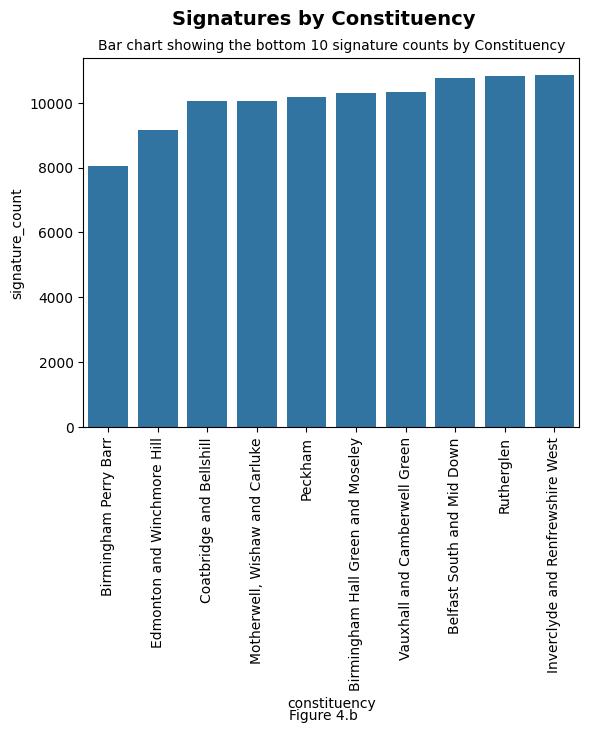

In [31]:
# creating bar plot with bottom 10 values
ax = sns.barplot(data = constituency_agg.sort_values(by='signature_count', ascending=True)[0:10], x="constituency", y="signature_count")
ax.tick_params(axis='x', labelrotation=90)
# adding text labels
plt.suptitle("Signatures by Constituency", fontsize=14, weight='bold')
plt.title("Bar chart showing the bottom 10 signature counts by Constituency", fontsize=10)
plt.figtext(0.5, -0.5, "Figure 4.b", ha="center", fontsize=10)
plt.show()

In [32]:
# importing relevant libraries for wordmap
from wordcloud import WordCloud, STOPWORDS

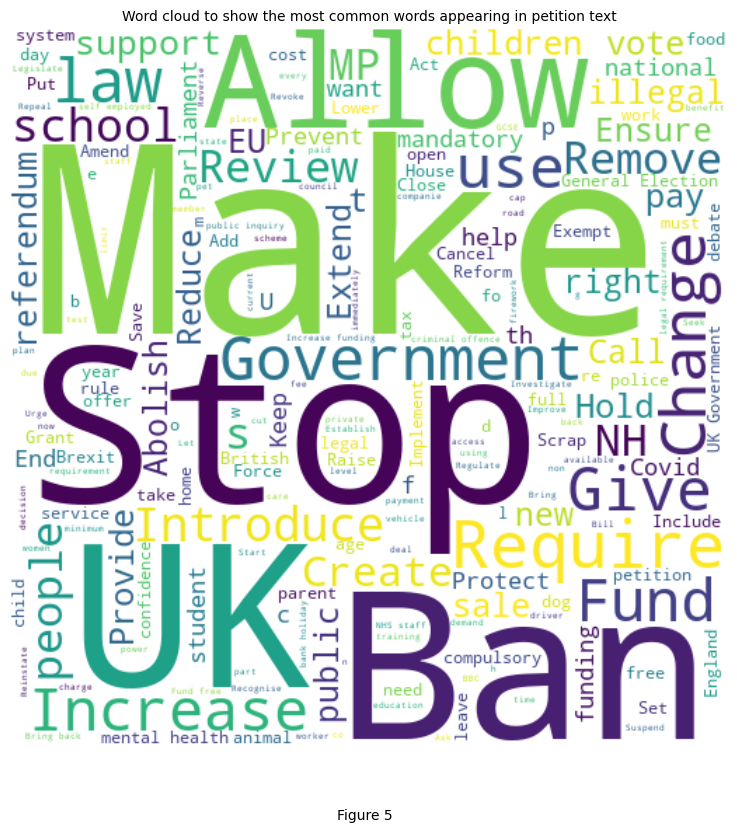

In [33]:
fig = plt.figure(figsize=(15,15))
# setting stop-words, so words like "the" and "it" are ignored
stopwords = set(STOPWORDS)

# petition text wordcloud
ax1 = fig.add_subplot(221)
a_wordcloud = WordCloud(width = 512, height = 512, background_color='white', stopwords=STOPWORDS).generate(petitions_df['text'].to_string())
ax1.imshow(a_wordcloud, interpolation='bilinear')

# adding text labels
plt.title("Word cloud to show the most common words appearing in petition text", fontsize=10)
plt.figtext(0.25, 0.45, "Figure 5", ha="center", fontsize=10)
ax1.axis('off')

fig.tight_layout()

### Reference
https://medium.com/analytics-vidhya/step-by-step-text-classification-using-different-models-and-compare-them-8a34204c34f8 